# 02 · Stable isotopes (Figure 10)

Code for: El Farchouni, A., et al. *Groundwater Recharge Mechanisms in the Haouz-Mejjate Aquifer (Morocco): Insights from Environmental Tracers and Self-Organizing Maps.* Groundwater for Sustainable Development, 101706. https://doi.org/10.1016/j.gsd.2026.101706

**What this notebook does**

Figure 10 of the article, two panels, from the 342 samples with δ¹⁸O and δ²H:
- **(a)** δ²H vs δ¹⁸O by water type against the Global Meteoric Water Line (GMWL, Craig, 1961) and the Local Meteoric Water Line of Morocco (LMWL, Ait Brahim et al., 2016), with the **Local Evaporation Line (LEL)** fitted by ordinary least squares through the evaporation-affected samples (d-excess < 8 ‰ and δ¹⁸O > -8 ‰).
- **(b)** δ¹⁸O vs sampling altitude of wells and springs with the **Local Altitudinal Line (LAL)** of Rhoujjati et al. (2021), used to estimate the recharge altitude of the non-evaporated groundwater samples.

Supporting figures: d-excess vs δ¹⁸O and d-excess by water type.

| | |
|---|---|
| **Input** | `outputs/intermediate/data_EMMA1.xlsx` (from `01_isotope_dataset.ipynb`) |
| **Figure** | `outputs/figures/Figure10_isotopes_LMWL_LEL_LAL.png` (+ `d_excess_vs_d18O_by_Type.png`, `d_excess_boxplot_by_Type.png`) |
| **Tables** | `outputs/tables/lel_results.txt`, `outputs/tables/altitude_results.txt`, `outputs/intermediate/isotopes_evap_classified.xlsx` |
| **Next notebook** | `05_EMMA/01_EMMA.ipynb` |

Reference lines:

| Line | Equation | Source |
|---|---|---|
| GMWL | δ²H = 8 δ¹⁸O + 10 | Craig (1961) |
| LMWL | δ²H = 7.73 δ¹⁸O + 9.18 | Ait Brahim et al. (2016) |
| LEL | fitted here (evaporation-affected samples) | this study |
| LAL | δ¹⁸O = -0.0027 × Z (gradient -0.27 ‰ per 100 m, Bouchaou et al., 1995) | Rhoujjati et al. (2021), Ourika catchment |
| Regional alternative | δ¹⁸O = -0.0018 × Z - 4.0 (gradient -0.18 ‰ per 100 m) | Ait Brahim et al. (2016), used for the uncertainty only |

d-excess = δ²H - 8 δ¹⁸O (Dansgaard, 1964).

### <font color='orange'> **1) Packages, settings and paths** </font>

In [1]:
# ── Core ──────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# ── Display settings ─────────────────────────────────────────────────
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 60)
pd.set_option('display.width', 120)

# ── Plot defaults (PNG only) ─────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 800,
    'font.size': 12,
    'axes.labelsize': 15,
    'axes.titlesize': 14,
    'figure.figsize': (10, 6),
    'savefig.bbox': 'tight',
    'savefig.transparent': False,
})

# ── Paths (built from the repository root, so they work on any computer) ──
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data").is_dir() and (p / "notebooks").is_dir())
DIR_INTERMED = ROOT / "outputs" / "intermediate"
DIR_TABLES   = ROOT / "outputs" / "tables"
DIR_FIGURES  = ROOT / "outputs" / "figures"
for d in (DIR_INTERMED, DIR_TABLES, DIR_FIGURES):
    d.mkdir(parents=True, exist_ok=True)
DATA_FILE = DIR_INTERMED / "data_EMMA1.xlsx"
print(f"  Input: {DATA_FILE.relative_to(ROOT)}  (exists: {DATA_FILE.is_file()})")

C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


  Input: outputs\intermediate\data_EMMA1.xlsx  (exists: True)


### <font color='orange'> **2) Load the isotope dataset and the water-type styles** </font>

> The input holds the samples with at least one isotope value; the 342 with both δ¹⁸O and δ²H are kept and their d-excess is computed. Groundwater samples are labelled "Groundwater (Wells)" in the figures, because springs are also groundwater.

In [2]:
df = pd.read_excel(DATA_FILE)
df["Type"] = df["Type"].replace({"Groundwater": "Groundwater (Wells)"})
print(f"Loaded: {len(df)} samples, {df.shape[1]} columns")

# Samples with both stable isotopes
O18, H2 = "δ18O (‰ VSMOW)", "δ2H (‰ VSMOW)"
df_iso = df[df[O18].notna() & df[H2].notna()].copy()
df_iso["d_excess"] = df_iso[H2] - 8 * df_iso[O18]          # Dansgaard (1964)
print(f"Samples with both δ18O and δ2H: {len(df_iso)}")
print(f"Samples with altitude (Z) among them: {df_iso['Z'].notna().sum()}")

# Marker and colour per water type (same in every figure)
TYPE_STYLE = {
    "Groundwater (Wells)": {"marker": "o", "color": "#1f77b4", "size": 40},
    "Spring":              {"marker": "^", "color": "#2ca02c", "size": 50},
    "Stream":              {"marker": "*", "color": "#d62728", "size": 60},
    "Snow":                {"marker": "D", "color": "#9467bd", "size": 40},
    "Rain":                {"marker": "v", "color": "#8c564b", "size": 45},
    "Dam":                 {"marker": "X", "color": "#e377c2", "size": 50},
    "Lac":                 {"marker": "P", "color": "#17becf", "size": 50},
    "Irrigation":          {"marker": "s", "color": "#bcbd22", "size": 40},
    "Canal (Zaraba)":      {"marker": "h", "color": "#ff7f0e", "size": 50},
}
missing_style = set(df_iso["Type"]) - set(TYPE_STYLE)
assert not missing_style, f"types without a style: {missing_style}"

print("")
print("Samples per water type (with both isotopes):")
print(df_iso["Type"].value_counts().to_string())
print(f"Total: {len(df_iso)}  (the figure caption gives n = 342)")

Loaded: 345 samples, 10 columns
Samples with both δ18O and δ2H: 342
Samples with altitude (Z) among them: 173

Samples per water type (with both isotopes):
Type
Groundwater (Wells)    158
Spring                  69
Stream                  41
Snow                    37
Rain                    21
Lac                     11
Dam                      2
Irrigation               2
Canal (Zaraba)           1
Total: 342  (the figure caption gives n = 342)


### <font color='orange'> **3) Reference lines and evaporation classification** </font>

- **GMWL** (Craig, 1961): δ²H = 8 δ¹⁸O + 10
- **LMWL** (Ait Brahim et al., 2016): δ²H = 7.73 δ¹⁸O + 9.18 (494 rain events, 17 stations across Morocco)
- **LAL, Local Altitudinal Line** (Rhoujjati et al., 2021, Ourika): δ¹⁸O = -0.0027 × Z, gradient -0.27 ‰ per 100 m (Bouchaou et al., 1995). The regional line of Ait Brahim et al. (2016), δ¹⁸O = -0.0018 × Z - 4.0 (gradient -0.18 ‰ per 100 m through -7.6 ‰ at 2,000 m), is kept as an alternative LAL to quantify the uncertainty of the altitude estimate (results file only).
- **LEL** (this study): ordinary least squares of δ²H on δ¹⁸O through the evaporation-affected samples, defined as d-excess < 8 ‰ and δ¹⁸O > -8 ‰ (the δ¹⁸O cut keeps depleted sublimated snow out of the fit). Because the samples are selected on d-excess, which is computed from the two regressed variables, the slope is descriptive only and no "source water" is derived from the intersection with the LMWL.

In [3]:
# Meteoric water lines
GMWL = lambda x: 8.0  * x + 10.0                     # Craig (1961)
LMWL_SLOPE, LMWL_INTERCEPT = 7.73, 9.18              # Ait Brahim et al. (2016)
LMWL = lambda x: LMWL_SLOPE * x + LMWL_INTERCEPT

# Local Altitudinal Lines (LAL): d18O = slope * Z + intercept  (Z in m a.s.l.)
LAL_LINES = {
    "LAL (Rhoujjati et al., 2021)":            {"slope": -0.0027, "intercept":  0.0, "role": "main"},
    "LAL alternative (Ait Brahim et al., 2016)": {"slope": -0.0018, "intercept": -4.0, "role": "alternative"},
}
def alt_from_d18O(d18O, line):
    """Recharge altitude (m) of a d18O value on the chosen LAL."""
    L = LAL_LINES[line]
    return (d18O - L["intercept"]) / L["slope"]
def d18O_from_alt(Z, line):
    L = LAL_LINES[line]
    return L["slope"] * Z + L["intercept"]

# Evaporation classification (thresholds used throughout the notebook)
DEXCESS_MAX = 8.0     # permil: below this d-excess a sample is evaporation-affected
D18O_MIN    = -8.0    # permil: the LEL is fitted only to enriched samples
df_iso["evap_group"] = np.where((df_iso["d_excess"] < DEXCESS_MAX) & (df_iso[O18] > D18O_MIN),
                                "evaporated", "non_evaporated")
df_evap = df_iso[df_iso["evap_group"] == "evaporated"]

# Local Evaporation Line (ordinary least squares)
lr = stats.linregress(df_evap[O18], df_evap[H2])
S_lel, b_lel, r2_lel = lr.slope, lr.intercept, lr.rvalue ** 2
sign = "+" if b_lel >= 0 else "-"
LEL = lambda x: S_lel * x + b_lel
LEL_LABEL = f"LEL: δ²H = {S_lel:.2f}·δ¹⁸O {sign} {abs(b_lel):.1f}  (r² = {r2_lel:.2f}, n = {len(df_evap)})"

print(f"Evaporated samples (d-excess < {DEXCESS_MAX:.0f} and δ18O > {D18O_MIN:.0f}): {len(df_evap)}")
print(f"Non-evaporated samples: {(df_iso['evap_group'] == 'non_evaporated').sum()}")
print(f"LEL: δ2H = {S_lel:.2f} δ18O {sign} {abs(b_lel):.2f}   slope SE = {lr.stderr:.2f}, intercept SE = {lr.intercept_stderr:.2f}, r² = {r2_lel:.3f}, p = {lr.pvalue:.1e}")
print("Evaporated samples by type:", df_evap["Type"].value_counts().to_dict())

print()
print("LAL, predicted d18O (permil) at reference altitudes:")
for Z in (500, 1000, 2000, 3000):
    print(f"  Z = {Z:>4d} m : " + "  |  ".join(f"{name} {d18O_from_alt(Z, name):+.2f}" for name in LAL_LINES))

Evaporated samples (d-excess < 8 and δ18O > -8): 57
Non-evaporated samples: 285
LEL: δ2H = 6.40 δ18O - 7.43   slope SE = 0.55, intercept SE = 3.24, r² = 0.713, p = 1.5e-16
Evaporated samples by type: {'Snow': 18, 'Spring': 16, 'Groundwater (Wells)': 15, 'Lac': 3, 'Dam': 2, 'Stream': 2, 'Rain': 1}

LAL, predicted d18O (permil) at reference altitudes:
  Z =  500 m : LAL (Rhoujjati et al., 2021) -1.35  |  LAL alternative (Ait Brahim et al., 2016) -4.90
  Z = 1000 m : LAL (Rhoujjati et al., 2021) -2.70  |  LAL alternative (Ait Brahim et al., 2016) -5.80
  Z = 2000 m : LAL (Rhoujjati et al., 2021) -5.40  |  LAL alternative (Ait Brahim et al., 2016) -7.60
  Z = 3000 m : LAL (Rhoujjati et al., 2021) -8.10  |  LAL alternative (Ait Brahim et al., 2016) -9.40


#### How the evaporated samples are defined

Evaporation leaves two fingerprints in the stable isotopes of a water sample:

1. **Low deuterium excess.** d-excess = δ²H - 8 δ¹⁸O (Dansgaard, 1964). Precipitation that has not evaporated plots on or near the meteoric water lines and has a d-excess close to 10 ‰ (GMWL) or higher. Evaporation from an open water surface fractionates ¹⁸O more than ²H relative to the slope of 8, so the sample moves **below** the meteoric lines and its d-excess drops. A threshold of **d-excess < 8 ‰** (2 ‰ below the GMWL value) is used to flag a sample as evaporation-affected: a common operational cut-off that leaves room for analytical uncertainty (about ±1 ‰ on d-excess) and for the natural scatter of local precipitation (the LMWL of Ait Brahim et al., 2016, has an intercept of 9.18 ‰).
2. **Enrichment in heavy isotopes.** Evaporation also shifts the remaining water toward heavier values (higher δ¹⁸O). A second condition, **δ¹⁸O > -8 ‰**, is therefore required. It keeps out the very depleted snow samples that show a low d-excess for another reason: sublimation and vapour exchange in the snowpack, which also lower the d-excess but do not represent liquid-water evaporation of recharge. Without this condition, several snow samples at -10 to -17 ‰ would enter the evaporation line and distort its slope.

A sample is classified as **evaporated** when both conditions hold; otherwise it is **non-evaporated**. The two thresholds are the constants `DEXCESS_MAX` and `D18O_MIN` of the code cell above.

How the classification is used:

- **Local Evaporation Line (Figure 10a).** Fitted to the evaporated samples only (n = 57: 18 snow, 16 springs, 15 wells, 3 lakes, 2 dams, 2 streams, 1 rain). The slope of 6.40, lower than 8, is the expected signature of kinetic evaporation under semi-arid conditions (Craig and Gordon, 1965; Gat, 1996; Clark and Fritz, 2013).
- **Recharge altitude (Figure 10b).** Only non-evaporated groundwater is projected onto the LAL. An evaporated sample has a δ¹⁸O that no longer reflects the altitude of its precipitation, so projecting it would give an altitude that is too low. The evaporated wells and springs are drawn as hollow symbols to show that they exist and that they are excluded.
- **Export (Section 8).** The classification of every sample is written to `isotopes_evap_classified.xlsx` for the EMMA notebook.

### <font color='orange'> **4) Figure 10a: δ²H versus δ¹⁸O with GMWL, LMWL and LEL** </font>

All 342 samples by water type, zoomed on the main cluster (samples outside the zoom are listed; the legend gives the full counts). The LEL is drawn across the whole axis like the other lines.

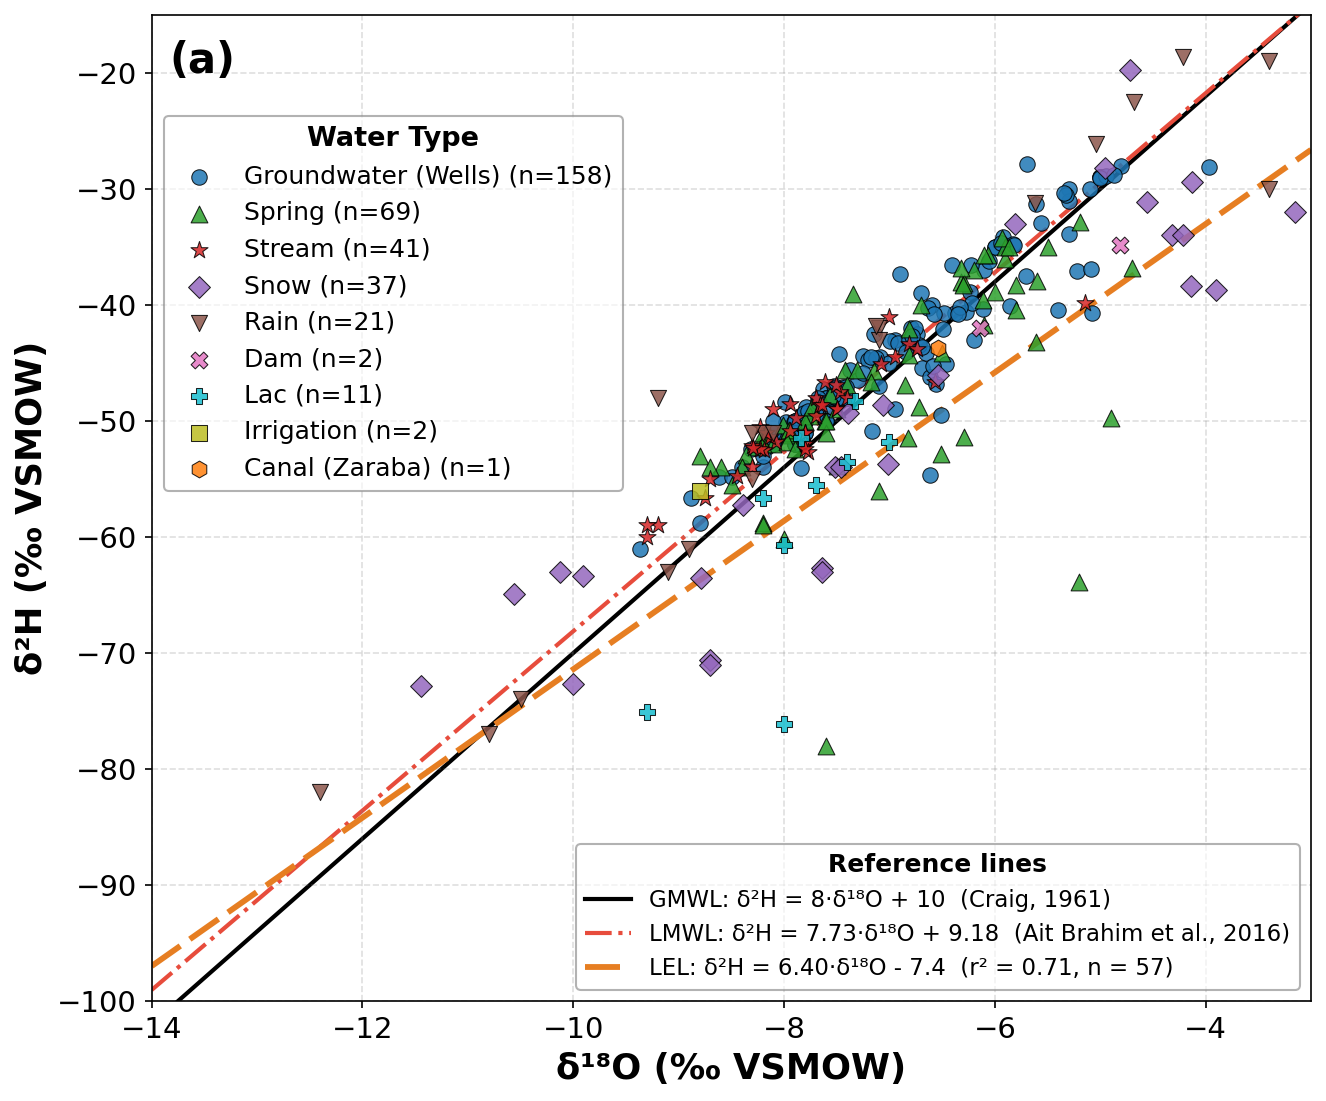

Plotted 327 of 342 samples inside the zoom window.
15 sample(s) outside the zoom window (not drawn):
SampleID                 Reference       Type  δ18O (‰ VSMOW)  δ2H (‰ VSMOW)
    S296 (Bouimouass et al., 2020)       Rain          -15.30        -111.00
    S307 (Bouimouass et al., 2020)       Rain          -18.10        -126.00
    S309 (Bouimouass et al., 2020)       Snow          -15.50        -104.00
    S310 (Bouimouass et al., 2020)       Snow          -17.10        -117.00
    S311 (Bouimouass et al., 2020)       Snow          -15.50        -106.00
    S316 (Bouimouass et al., 2020) Irrigation           -8.10          50.00
    S481  (Rhoujjati et al., 2021)       Snow           -2.41         -21.98
    S488  (Rhoujjati et al., 2021)       Snow           -2.52         -33.50
    S493  (Rhoujjati et al., 2021)       Snow           -2.91         -28.20
    S499  (Rhoujjati et al., 2021)       Snow          -14.70        -116.00
    S500  (Rhoujjati et al., 2021)       Snow       

In [4]:
# Font sizes shared by the manuscript figures
LABEL_FS, TICK_FS, LEG_FS, LEG_TITLE_FS, ANNO_FS, PANEL_LBL_FS = 17, 14, 12, 13, 12, 20
LEG_ALPHA = 0.6   # legend transparency, so points behind a legend stay visible

def draw_panel_a(ax, label="(a)"):
    """δ2H versus δ18O with GMWL, LMWL and LEL, samples by water type."""
    X_MIN, X_MAX, Y_MIN, Y_MAX = -14, -3, -100, -15
    inside = df_iso[(df_iso[O18].between(X_MIN, X_MAX)) & (df_iso[H2].between(Y_MIN, Y_MAX))]
    outside = df_iso.drop(inside.index)

    x = np.linspace(X_MIN, X_MAX, 100)
    ax.plot(x, GMWL(x), "k-", lw=2.0, zorder=1, label="GMWL: δ²H = 8·δ¹⁸O + 10  (Craig, 1961)")
    ax.plot(x, LMWL(x), "-.", color="#E74C3C", lw=2.0, zorder=1,
            label="LMWL: δ²H = 7.73·δ¹⁸O + 9.18  (Ait Brahim et al., 2016)")
    ax.plot(x, LEL(x), color="#E67E22", lw=2.8, ls=(0, (6, 2)), zorder=2, label=LEL_LABEL)   # drawn across the full axis like the other lines

    for wtype, st in TYPE_STYLE.items():
        sub = inside[inside["Type"] == wtype]
        if (df_iso["Type"] == wtype).sum() == 0:
            continue
        ax.scatter(sub[O18], sub[H2], marker=st["marker"], c=st["color"], s=st["size"] + 15,
                   edgecolors="black", linewidths=0.5, alpha=0.85, zorder=3,
                   label=f"{wtype} (n={(df_iso['Type'] == wtype).sum()})")   # full count, 342 in total

    ax.set_xlim(X_MIN, X_MAX); ax.set_ylim(Y_MIN, Y_MAX)
    ax.set_xlabel("δ¹⁸O (‰ VSMOW)", fontsize=LABEL_FS, fontweight="bold")
    ax.set_ylabel("δ²H (‰ VSMOW)", fontsize=LABEL_FS, fontweight="bold")
    ax.tick_params(axis="both", labelsize=TICK_FS)
    ax.grid(True, ls="--", alpha=0.25, color="gray")

    h, l = ax.get_legend_handles_labels()
    leg_lines = ax.legend(h[:3], l[:3], loc="lower right", fontsize=LEG_FS - 1, framealpha=LEG_ALPHA,
                          edgecolor="gray", title="Reference lines", title_fontsize=LEG_TITLE_FS - 1)
    leg_lines.get_title().set_fontweight("bold")
    ax.add_artist(leg_lines)
    leg_types = ax.legend(h[3:], l[3:], loc="upper left", bbox_to_anchor=(0.0, 0.91), fontsize=LEG_FS,
                          framealpha=LEG_ALPHA, edgecolor="gray", title="Water Type", title_fontsize=LEG_TITLE_FS)
    leg_types.get_title().set_fontweight("bold")
    ax.text(0.015, 0.975, label, transform=ax.transAxes, fontsize=PANEL_LBL_FS, fontweight="bold",
            va="top", ha="left", zorder=20)
    return inside, outside

fig, ax = plt.subplots(figsize=(9, 7.5))
inside_a, outside_a = draw_panel_a(ax)
plt.tight_layout()
plt.show()

print(f"Plotted {len(inside_a)} of {len(df_iso)} samples inside the zoom window.")
if len(outside_a):
    print(f"{len(outside_a)} sample(s) outside the zoom window (not drawn):")
    print(outside_a[["SampleID", "Reference", "Type", O18, H2]].to_string(index=False))
print("Legend counts are the totals per type (sum 342); the samples listed above are outside the window.")

### <font color='orange'> **5) Figure 10b: δ¹⁸O versus altitude and recharge-altitude estimate** </font>

Groundwater only (wells and springs); surface waters, snow and rain are not shown because a recharge altitude has no meaning for them. Points are drawn at their sampling altitude. The recharge altitude is read on the LAL from δ¹⁸O for all **non-evaporated groundwater samples** (d-excess ≥ 8 ‰); evaporated samples (hollow symbols) are never projected. Each non-evaporated well and spring is projected horizontally onto the LAL and down to the altitude axis; the shaded area under the LAL spans the recharge-altitude range of the projected samples (the two dashed boundaries start at the most enriched and most depleted samples that have a sampling altitude). The estimate is reported as median, interquartile range and full range for all groundwater, and separately for springs and wells, on the main LAL and, in the results file only, on the alternative LAL as the uncertainty. The figure shows the main LAL only, with the minimum and maximum of the samples used.

Recharge altitude from d18O on the Local Altitudinal Line (notebook 04_isotopes/02_isotopes)
Estimate: all non-evaporated groundwater (wells + springs, d-excess >= 8 permil); springs and wells also given separately.
Groundwater n = 196 (d18O -9.37 to -4.80, median -7.49 permil)
Springs     n = 53 (d18O -8.80 to -5.20, median -7.56 permil)
Wells       n = 143 (d18O -9.37 to -4.80, median -7.48 permil)

LAL (Rhoujjati et al., 2021): d18O = -0.0027 * Z + 0.0
   groundwater    n=196  min  1778  Q1  2392  median  2774  Q3  2926  max  3470 m
   with altitude  n=115  min  1805  Q1  2358  median  2685  Q3  2891  max  3470 m
   springs        n= 53  min  1924  Q1  2333  median  2800  Q3  2967  max  3259 m
   wells          n=143  min  1778  Q1  2440  median  2771  Q3  2901  max  3470 m

LAL alternative (Ait Brahim et al., 2016): d18O = -0.0018 * Z - 4.0
   groundwater    n=196  min   444  Q1  1366  median  1939  Q3  2167  max  2983 m
   with altitude  n=115  min   485  Q1  1315  median  1806  Q

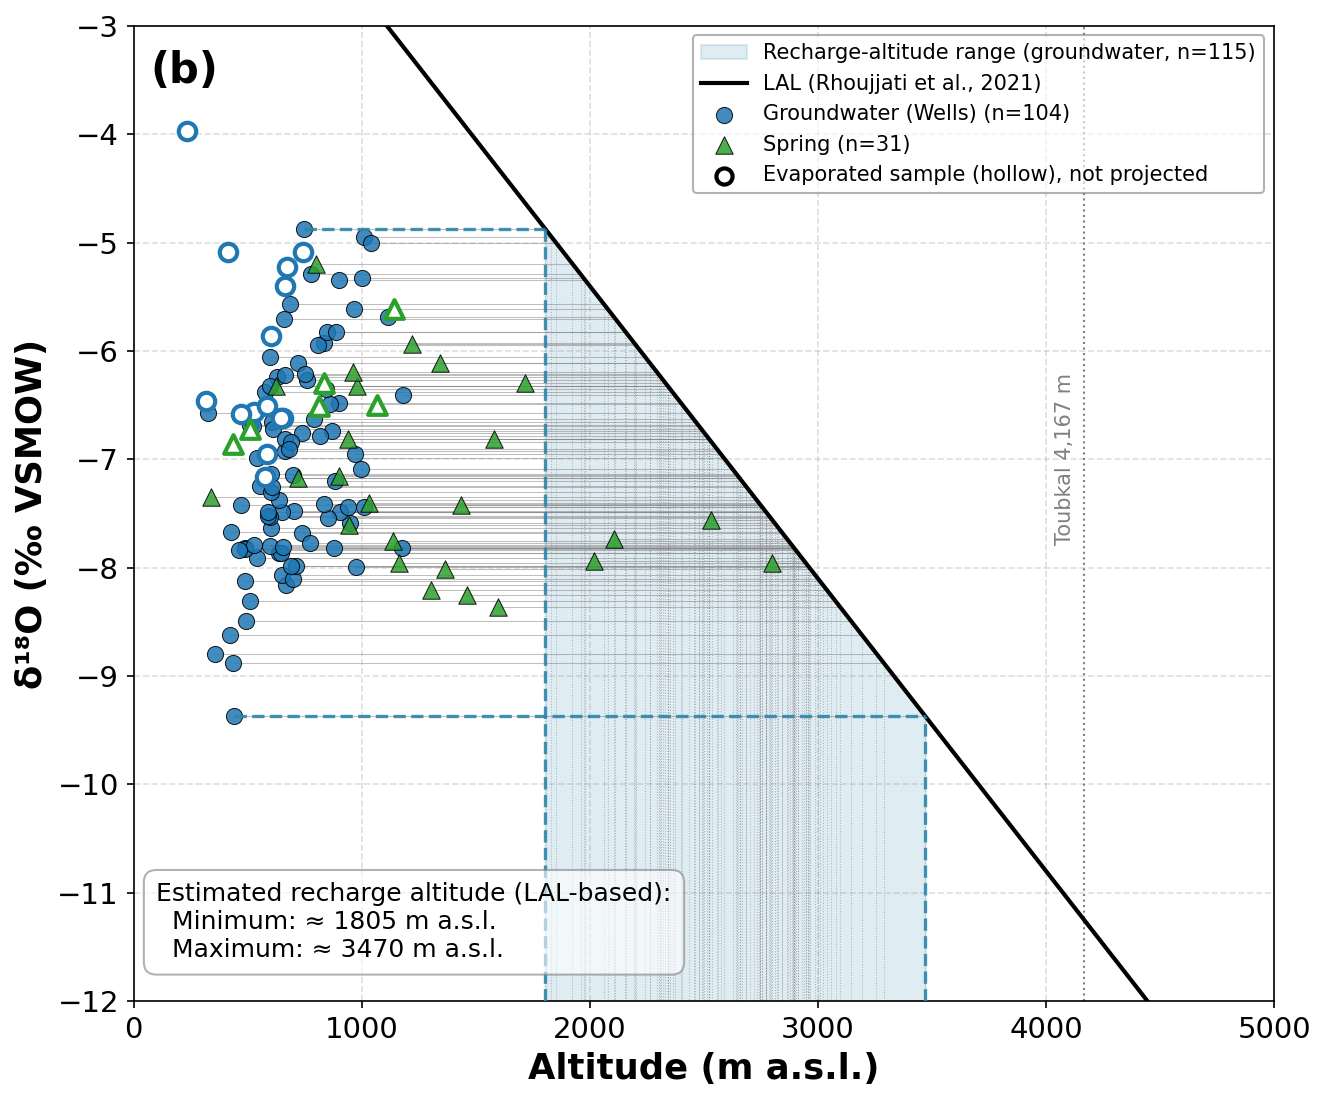

For the caption and the text: non-evaporated groundwater with altitude, n = 115: median 2685 m, interquartile 2358 to 2891 m, range 1805 to 3470 m a.s.l. (alternative LAL of Ait Brahim et al., 2016: median 1806 m, range 485 to 2983 m)


In [5]:
# Samples used for the recharge-altitude estimate (the projection uses d18O only, no sampling altitude needed)
MAIN_LAL, ALT_LAL = "LAL (Rhoujjati et al., 2021)", "LAL alternative (Ait Brahim et al., 2016)"
non_evap  = df_iso["evap_group"] == "non_evaporated"
sel_springs = df_iso[non_evap & (df_iso["Type"] == "Spring")]
sel_wells   = df_iso[non_evap & (df_iso["Type"] == "Groundwater (Wells)")]
sel_pub     = df_iso[non_evap & df_iso["Type"].isin(["Spring", "Groundwater (Wells)"])]   # all non-evaporated groundwater

def altitude_stats(sub, line):
    alt = alt_from_d18O(sub[O18], line)
    q = alt.quantile([0, 0.25, 0.5, 0.75, 1.0]).values
    return dict(n=len(sub), min=q[0], q1=q[1], median=q[2], q3=q[3], max=q[4])

sel_drawn = sel_pub[sel_pub["Z"].notna()]      # the samples the figure can draw (known sampling altitude)
ALT_STATS = {name: {"groundwater": altitude_stats(sel_pub, name),
                    "groundwater_drawn": altitude_stats(sel_drawn, name),
                    "springs": altitude_stats(sel_springs, name),
                    "wells": altitude_stats(sel_wells, name)} for name in LAL_LINES}

out = ["Recharge altitude from d18O on the Local Altitudinal Line (notebook 04_isotopes/02_isotopes)",
       "Estimate: all non-evaporated groundwater (wells + springs, d-excess >= 8 permil); springs and wells also given separately.",
       f"Groundwater n = {len(sel_pub)} (d18O {sel_pub[O18].min():.2f} to {sel_pub[O18].max():.2f}, median {sel_pub[O18].median():.2f} permil)",
       f"Springs     n = {len(sel_springs)} (d18O {sel_springs[O18].min():.2f} to {sel_springs[O18].max():.2f}, median {sel_springs[O18].median():.2f} permil)",
       f"Wells       n = {len(sel_wells)} (d18O {sel_wells[O18].min():.2f} to {sel_wells[O18].max():.2f}, median {sel_wells[O18].median():.2f} permil)",
       ""]
for name, L in LAL_LINES.items():
    sgn = "+" if L["intercept"] >= 0 else "-"
    out.append(f"{name}: d18O = {L['slope']:.4f} * Z {sgn} {abs(L['intercept']):.1f}")
    for key, lab in (("groundwater", "groundwater"), ("groundwater_drawn", "with altitude"), ("springs", "springs"), ("wells", "wells")):
        st = ALT_STATS[name][key]
        out.append(f"   {lab:14s} n={st['n']:3d}  min {st['min']:5.0f}  Q1 {st['q1']:5.0f}  median {st['median']:5.0f}  Q3 {st['q3']:5.0f}  max {st['max']:5.0f} m")
    out.append("")
report = chr(10).join(out)
print(report)
with open(DIR_TABLES / "altitude_results.txt", "w", encoding="utf-8") as fh:
    fh.write(report)
print("Saved: outputs/tables/altitude_results.txt")
_ext = sel_pub[sel_pub["Z"].notna()]
print(f"Boundary samples drawn in the figure (with a sampling altitude): most enriched {_ext.loc[_ext[O18].idxmax(), 'SampleID']} "
      f"({_ext[O18].max():.2f} permil, {alt_from_d18O(_ext[O18].max(), MAIN_LAL):.0f} m), most depleted {_ext.loc[_ext[O18].idxmin(), 'SampleID']} "
      f"({_ext[O18].min():.2f} permil, {alt_from_d18O(_ext[O18].min(), MAIN_LAL):.0f} m). The figure (shading, boundaries, text box) uses these {len(_ext)} samples; altitude_results.txt also gives all {len(sel_pub)}.")

# ── Panel (b) ────────────────────────────────────────────────────────
def draw_panel_b(ax, label="(b)"):
    """d18O versus altitude, groundwater only, with the LAL and the recharge-altitude band."""
    Z_MIN, Z_MAX, Y_MIN, Y_MAX = 0, 5000, -12, -3
    st = ALT_STATS[MAIN_LAL]["groundwater_drawn"]     # figure: samples with a sampling altitude
    z = np.linspace(Z_MIN, Z_MAX, 200)

    # Recharge-altitude range: shaded under the main LAL, from the minimum to the maximum altitude
    zr = np.linspace(st["min"], st["max"], 100)
    ax.fill_between(zr, Y_MIN, d18O_from_alt(zr, MAIN_LAL), color="#2E86AB", alpha=0.15, zorder=0,
                    label=f"Recharge-altitude range (groundwater, n={st['n']})")
    # Boundaries drawn from the two extreme samples that have a sampling altitude: horizontally to the LAL, then down
    ext = sel_pub[sel_pub["Z"].notna()]
    for idx in (ext[O18].idxmax(), ext[O18].idxmin()):
        r = ext.loc[idx]
        za = alt_from_d18O(r[O18], MAIN_LAL)
        ax.plot([r["Z"], za], [r[O18], r[O18]], color="#2E86AB", ls="--", lw=1.6, alpha=0.9, zorder=6)
        ax.plot([za, za], [Y_MIN, r[O18]], color="#2E86AB", ls="--", lw=1.6, alpha=0.9, zorder=6)

    # Projection of each non-evaporated well and spring onto the main LAL (horizontal to the line, then down to the axis)
    for _, r in sel_pub[sel_pub["Z"].notna()].iterrows():
        za = alt_from_d18O(r[O18], MAIN_LAL)
        ax.plot([r["Z"], za], [r[O18], r[O18]], color="gray", lw=0.5, alpha=0.5, zorder=1)
        ax.plot([za, za], [r[O18], Y_MIN], color="gray", lw=0.5, alpha=0.5, zorder=1, ls=":")

    # Lines
    ax.plot(z, d18O_from_alt(z, MAIN_LAL), "k-", lw=2.0, zorder=2, label="LAL (Rhoujjati et al., 2021)")   # same width as the GMWL in (a)
    ax.axvline(4167, color="gray", ls=":", lw=1.0, zorder=1)
    ax.text(4167 - 40, -7.0, "Toubkal 4,167 m", rotation=90, va="center", ha="right",
            fontsize=ANNO_FS - 2, color="gray")

    # Groundwater with a sampling altitude: filled = non-evaporated, hollow = evaporated (not used)
    gw = df_iso[df_iso["Z"].notna() & df_iso["Type"].isin(["Groundwater (Wells)", "Spring"])]
    for wtype in ["Groundwater (Wells)", "Spring"]:
        stl = TYPE_STYLE[wtype]
        sub = gw[gw["Type"] == wtype]
        ok = sub["evap_group"] == "non_evaporated"
        ax.scatter(sub.loc[ok, "Z"], sub.loc[ok, O18], marker=stl["marker"], c=stl["color"],
                   s=stl["size"] + 20, edgecolors="black", linewidths=0.5, alpha=0.85, zorder=4,
                   label=f"{wtype} (n={len(sub)})")
        ax.scatter(sub.loc[~ok, "Z"], sub.loc[~ok, O18], marker=stl["marker"], facecolors="white",
                   edgecolors=stl["color"], s=stl["size"] + 30, linewidths=2.0, alpha=1.0, zorder=5)
    ax.scatter([], [], marker="o", facecolors="white", edgecolors="black", s=60, linewidths=2.0,
               label="Evaporated sample (hollow), not projected")

    ax.set_xlim(Z_MIN, Z_MAX)
    ax.set_ylim(Y_MIN, Y_MAX)
    ax.set_xlabel("Altitude (m a.s.l.)", fontsize=LABEL_FS, fontweight="bold")
    ax.set_ylabel("δ¹⁸O (‰ VSMOW)", fontsize=LABEL_FS, fontweight="bold")
    ax.tick_params(axis="both", labelsize=TICK_FS)
    ax.grid(True, ls="--", alpha=0.25, color="gray")

    # Compact range box from the samples used in the figure
    txt = ("Estimated recharge altitude (LAL-based):" + chr(10)
           + f"  Minimum: ≈ {st['min']:.0f} m a.s.l." + chr(10)
           + f"  Maximum: ≈ {st['max']:.0f} m a.s.l.")
    ax.text(0.02, 0.04, txt, transform=ax.transAxes, fontsize=ANNO_FS, va="bottom", ha="left", zorder=30,
            bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="gray", alpha=LEG_ALPHA))

    h, l = ax.get_legend_handles_labels()
    leg = ax.legend(h, l, loc="upper right", bbox_to_anchor=(0.995, 0.995), fontsize=LEG_FS - 2,
                    framealpha=LEG_ALPHA, edgecolor="gray", borderaxespad=0.2, handlelength=2.2)
    leg.set_zorder(30)
    ax.text(0.015, 0.975, label, transform=ax.transAxes, fontsize=PANEL_LBL_FS, fontweight="bold",
            va="top", ha="left", zorder=20)

fig, ax = plt.subplots(figsize=(9, 7.5))
draw_panel_b(ax)
plt.tight_layout()
plt.show()
st_fig = ALT_STATS[MAIN_LAL]["groundwater_drawn"]
print(f"For the caption and the text: non-evaporated groundwater with altitude, n = {st_fig['n']}: median {st_fig['median']:.0f} m, "
      f"interquartile {st_fig['q1']:.0f} to {st_fig['q3']:.0f} m, range {st_fig['min']:.0f} to {st_fig['max']:.0f} m a.s.l. "
      f"(alternative LAL of Ait Brahim et al., 2016: median {ALT_STATS[ALT_LAL]['groundwater_drawn']['median']:.0f} m, "
      f"range {ALT_STATS[ALT_LAL]['groundwater_drawn']['min']:.0f} to {ALT_STATS[ALT_LAL]['groundwater_drawn']['max']:.0f} m)")

### <font color='orange'> **6) Figure 10 for the manuscript: panels (a) and (b) side by side** </font>

Same drawing functions as Sections 4 and 5, assembled in one figure (two panels, 18 x 7.5 inches, 800 dpi).

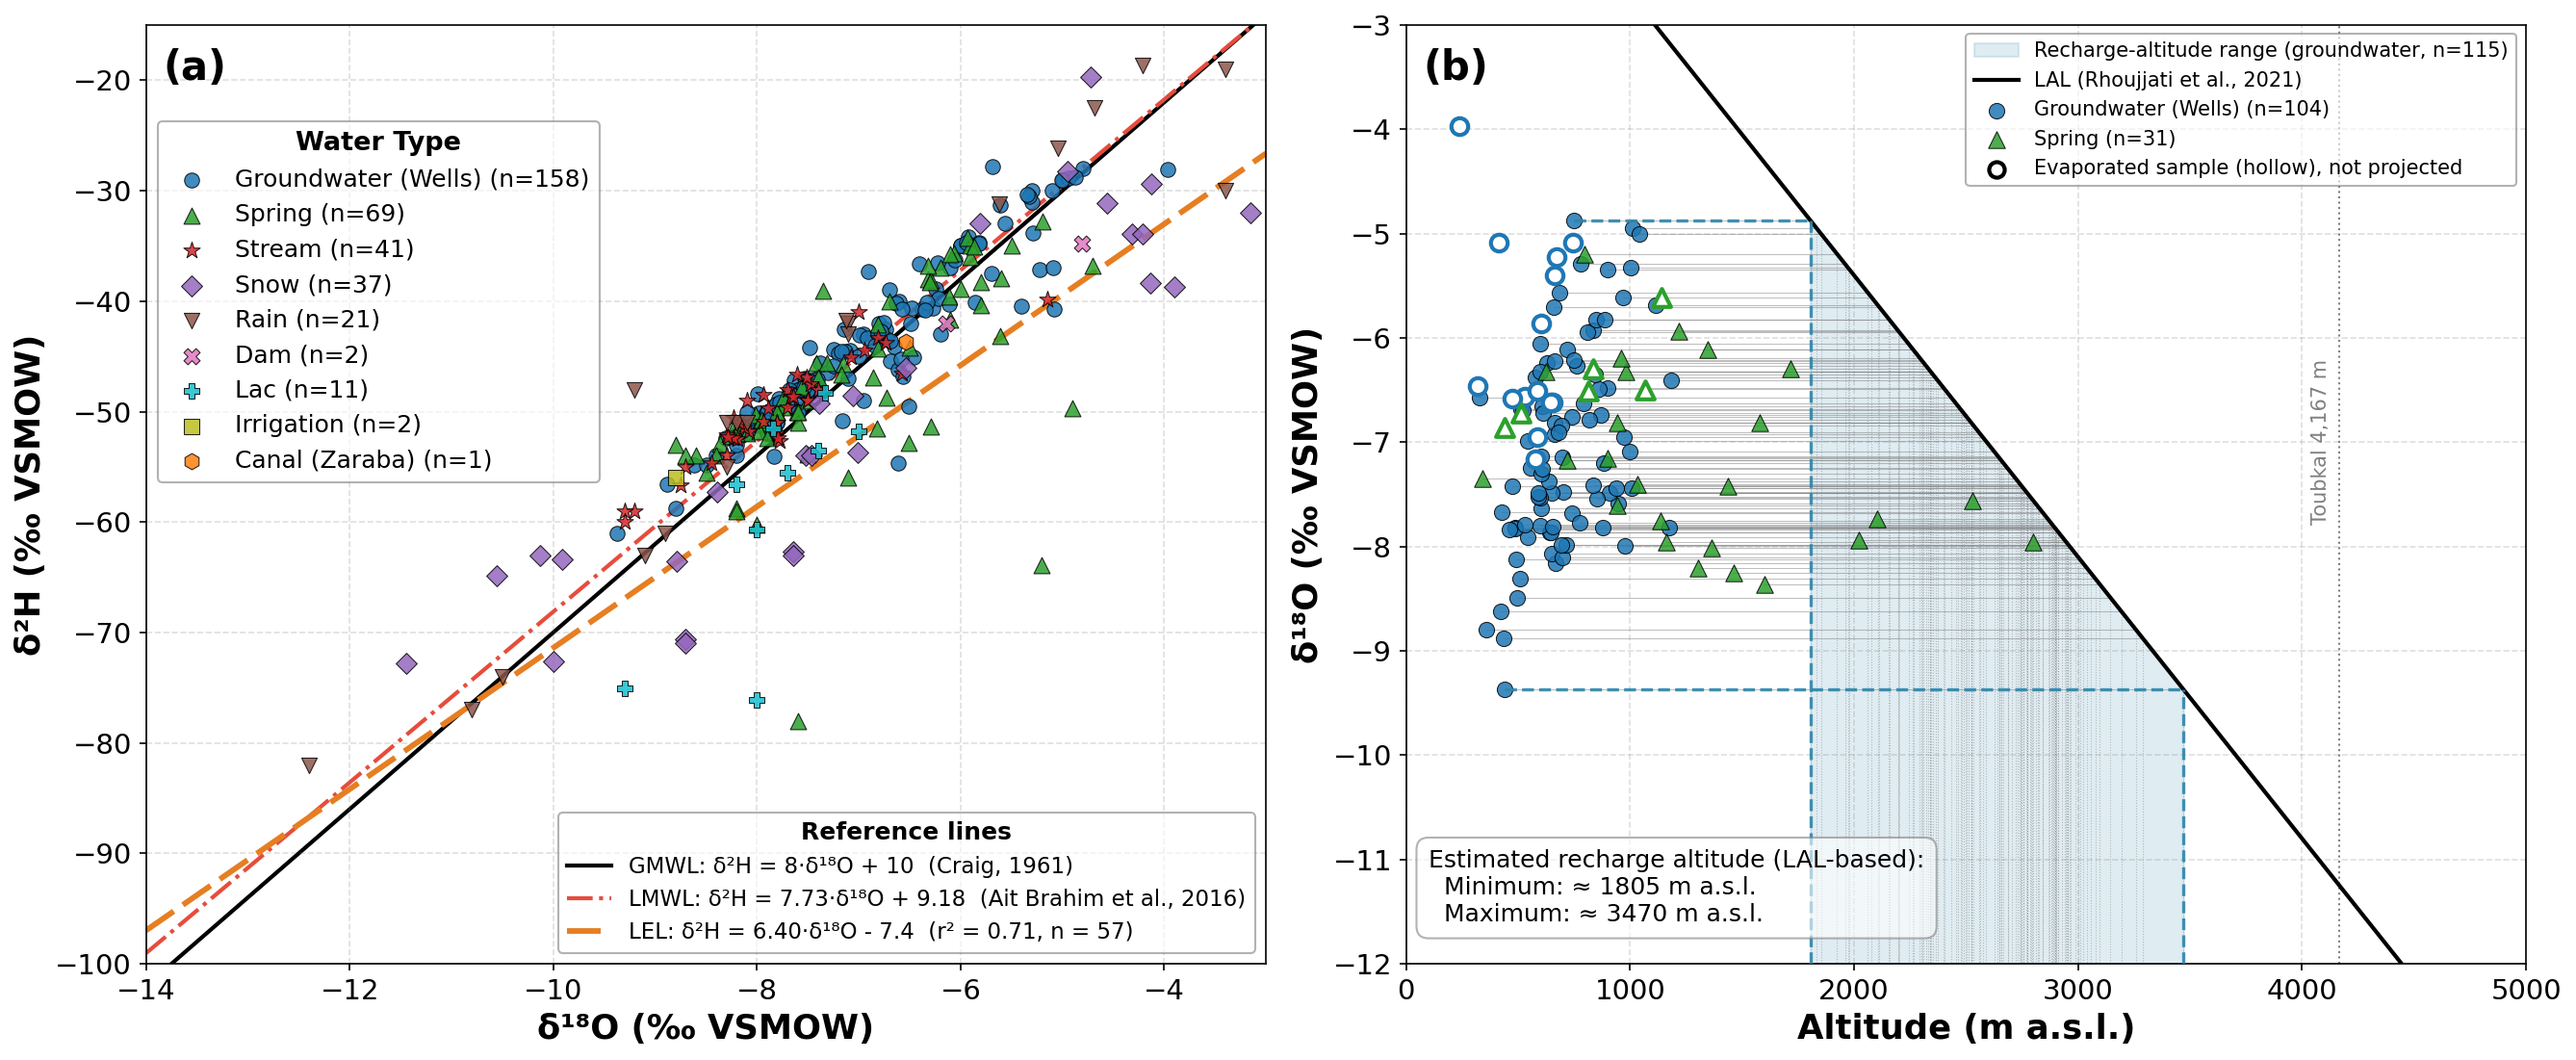

Saved: outputs\figures\Figure10_isotopes_LMWL_LEL_LAL.png


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7.5))
draw_panel_a(ax1, label="(a)")
draw_panel_b(ax2, label="(b)")
plt.tight_layout()
FIG10 = DIR_FIGURES / "Figure10_isotopes_LMWL_LEL_LAL.png"
fig.savefig(FIG10, dpi=800)
plt.show()
print("Saved:", FIG10.relative_to(ROOT))

### <font color='orange'> **7) d-excess plots (supporting figures)** </font>

d-excess = δ²H - 8 δ¹⁸O (Dansgaard, 1964). Values near 10 ‰ indicate oceanic (Atlantic) moisture without evaporation, higher values a Mediterranean or recycled moisture component, lower values evaporation before or during infiltration. Two figures: d-excess versus δ¹⁸O by water type (the evaporation threshold of 8 ‰ is shown), and boxplots of d-excess by water type.

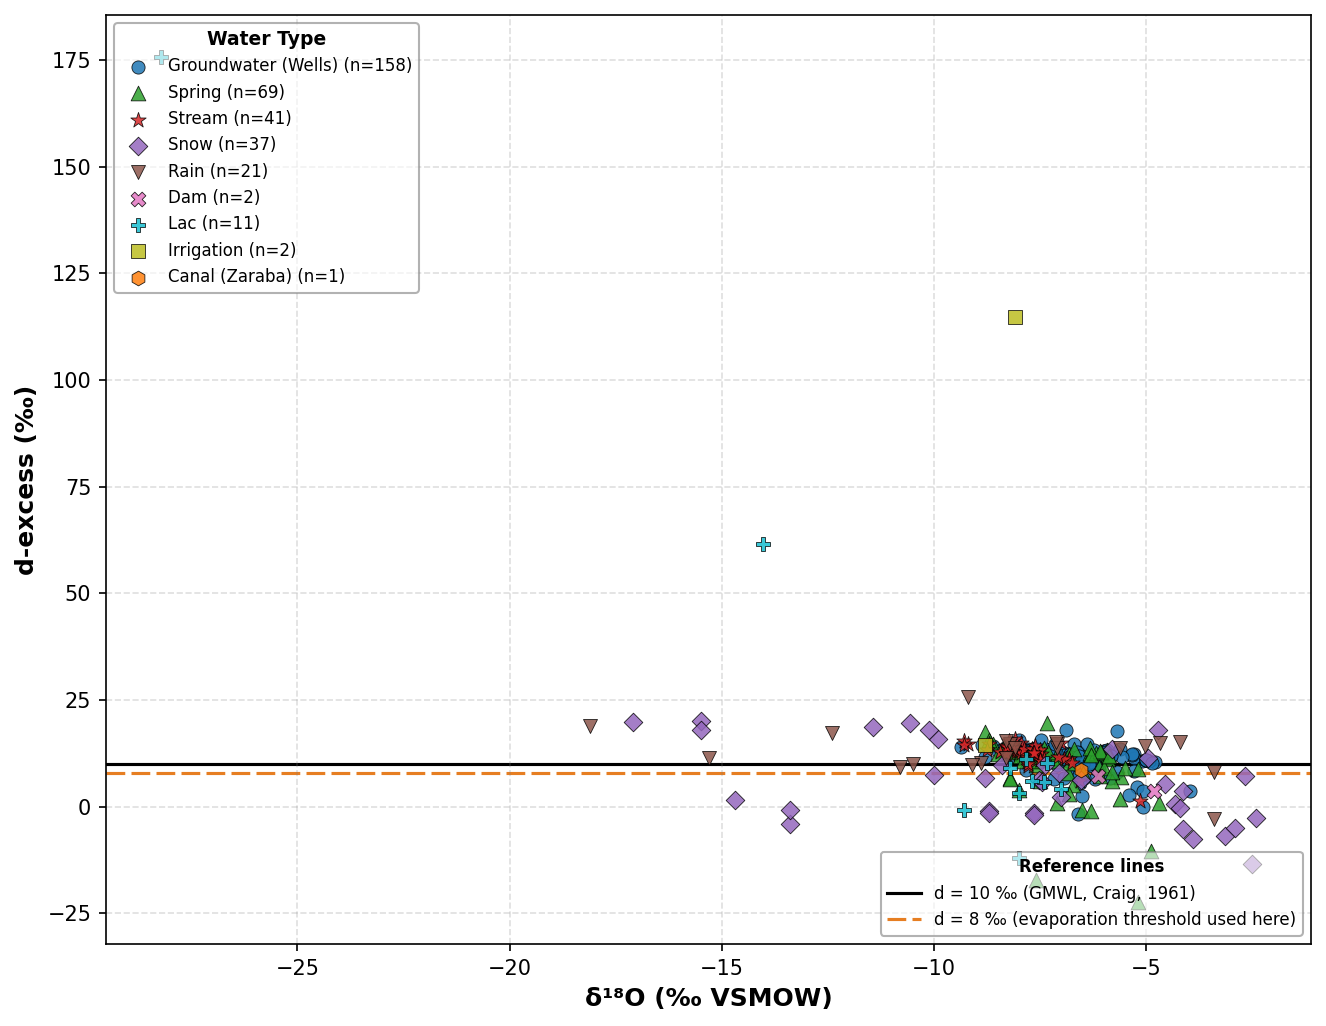

Saved: d_excess_vs_d18O_by_Type.png


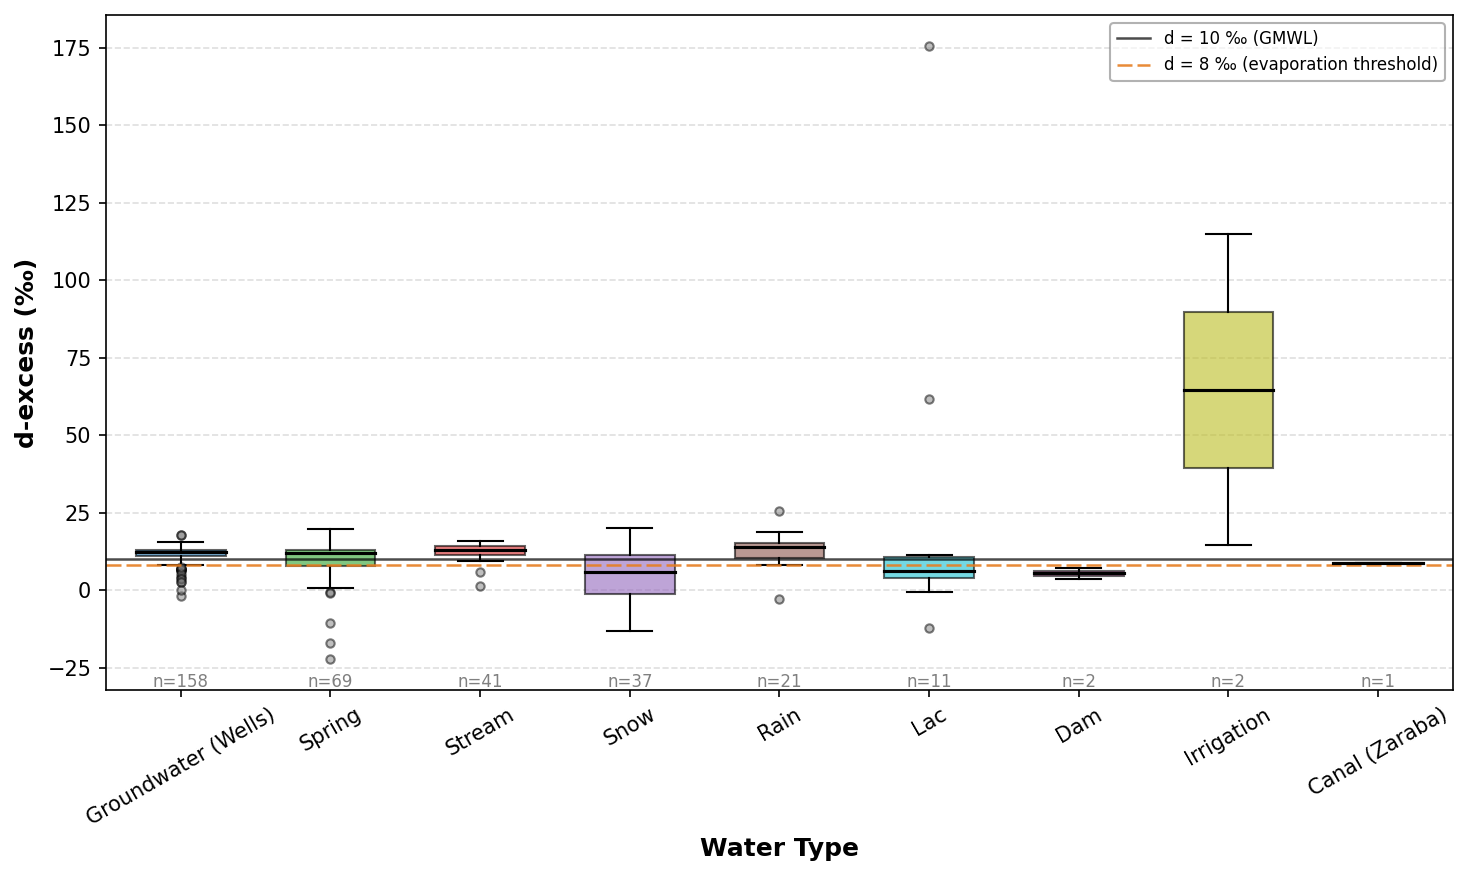

Saved: d_excess_boxplot_by_Type.png

d-excess by water type (permil):
                     count  mean   50%   min    max
Type                                               
Canal (Zaraba)         1.0   8.6   8.6   8.6    8.6
Dam                    2.0   5.4   5.4   3.7    7.1
Groundwater (Wells)  158.0  11.5  12.2  -1.8   17.9
Irrigation             2.0  64.6  64.6  14.4  114.8
Lac                   11.0  24.9   6.1 -12.1  175.6
Rain                  21.0  13.1  13.8  -2.8   25.6
Snow                  37.0   5.5   5.7 -13.3   20.0
Spring                69.0   9.3  11.9 -22.3   19.7
Stream                41.0  12.4  12.8   1.4   15.8


In [7]:
df_dex = df_iso.copy()

# ── 7a) d-excess versus d18O ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 7))
ax.axhline(10, color="k", ls="-", lw=1.5, zorder=1, label="d = 10 ‰ (GMWL, Craig, 1961)")
ax.axhline(DEXCESS_MAX, color="#E67E22", ls=(0, (6, 2)), lw=1.5, zorder=1,
           label=f"d = {DEXCESS_MAX:.0f} ‰ (evaporation threshold used here)")
for wtype, st in TYPE_STYLE.items():
    sub = df_dex[df_dex["Type"] == wtype]
    if len(sub) == 0:
        continue
    ax.scatter(sub[O18], sub["d_excess"], marker=st["marker"], c=st["color"], s=st["size"],
               edgecolors="black", linewidths=0.4, alpha=0.85, zorder=3, label=f"{wtype} (n={len(sub)})")
ax.set_xlabel("δ¹⁸O (‰ VSMOW)", fontsize=12, fontweight="bold")
ax.set_ylabel("d-excess (‰)", fontsize=12, fontweight="bold")
ax.tick_params(axis="both", labelsize=10)
ax.grid(True, ls="--", alpha=0.25, color="gray")
h, l = ax.get_legend_handles_labels()
leg1 = ax.legend(h[:2], l[:2], loc="lower right", fontsize=8, framealpha=LEG_ALPHA, edgecolor="gray",
                 title="Reference lines", title_fontsize=8)
leg1.get_title().set_fontweight("bold")
ax.add_artist(leg1)
leg2 = ax.legend(h[2:], l[2:], loc="upper left", fontsize=8, framealpha=LEG_ALPHA, edgecolor="gray",
                 title="Water Type", title_fontsize=9)
leg2.get_title().set_fontweight("bold")
plt.tight_layout()
fig.savefig(DIR_FIGURES / "d_excess_vs_d18O_by_Type.png", dpi=800)
plt.show()
print("Saved: d_excess_vs_d18O_by_Type.png")

# ── 7b) boxplots of d-excess by water type ───────────────────────────
type_order = df_dex["Type"].value_counts().index.tolist()
box_colors = [TYPE_STYLE[t]["color"] for t in type_order]
fig, ax = plt.subplots(figsize=(10, 6))
bp = ax.boxplot([df_dex.loc[df_dex["Type"] == t, "d_excess"].values for t in type_order],
                labels=type_order, patch_artist=True, widths=0.6, showfliers=True,
                flierprops=dict(marker="o", markersize=4, markerfacecolor="gray", alpha=0.5),
                medianprops=dict(color="black", lw=1.5), whiskerprops=dict(color="black", lw=1),
                capprops=dict(color="black", lw=1))
for patch, color in zip(bp["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
    patch.set_edgecolor("black")
ax.axhline(10, color="k", ls="-", lw=1.2, alpha=0.7, label="d = 10 ‰ (GMWL)")
ax.axhline(DEXCESS_MAX, color="#E67E22", ls=(0, (6, 2)), lw=1.2, alpha=0.9, label=f"d = {DEXCESS_MAX:.0f} ‰ (evaporation threshold)")
for i, t in enumerate(type_order):
    ax.text(i + 1, ax.get_ylim()[0] + 1, f"n={(df_dex['Type'] == t).sum()}", ha="center", fontsize=8, color="gray")
ax.set_ylabel("d-excess (‰)", fontsize=12, fontweight="bold")
ax.set_xlabel("Water Type", fontsize=12, fontweight="bold")
ax.tick_params(axis="both", labelsize=10)
ax.tick_params(axis="x", rotation=30)
ax.grid(True, axis="y", ls="--", alpha=0.25, color="gray")
ax.legend(loc="upper right", fontsize=8, framealpha=LEG_ALPHA, edgecolor="gray")
plt.tight_layout()
fig.savefig(DIR_FIGURES / "d_excess_boxplot_by_Type.png", dpi=800)
plt.show()
print("Saved: d_excess_boxplot_by_Type.png")

print()
print("d-excess by water type (permil):")
print(df_dex.groupby("Type")["d_excess"].describe()[["count", "mean", "50%", "min", "max"]].round(1).to_string())

### <font color='orange'> **8) Export of results and check against the article** </font>

Writes `lel_results.txt` (next to `altitude_results.txt` written in Section 5) and `isotopes_evap_classified.xlsx` (every sample with its d-excess and its evaporation class, used by the EMMA notebook), then checks the key numbers of Section 3.6 and the Figure 10 caption.

In [8]:
# LEL results
lel_txt = chr(10).join([
    "Local Evaporation Line (LEL), notebook 04_isotopes/02_isotopes",
    f"Classification: d-excess < {DEXCESS_MAX:.0f} permil AND d18O > {D18O_MIN:.0f} permil",
    f"Evaporated samples (n)    : {len(df_evap)}  ({df_evap['Type'].value_counts().to_dict()})",
    f"Non-evaporated samples (n): {(df_iso['evap_group'] == 'non_evaporated').sum()}",
    f"LEL slope                 : {S_lel:.2f} (SE {lr.stderr:.2f})",
    f"LEL intercept             : {b_lel:.2f} (SE {lr.intercept_stderr:.2f})",
    f"R-squared                 : {r2_lel:.3f}",
    f"p-value                   : {lr.pvalue:.2e}",
    f"LEL equation              : d2H = {S_lel:.2f} * d18O {sign} {abs(b_lel):.2f}",
    "Note: the fit is conditioned on the d-excess selection, so the slope is indicative; no source water is derived.",
])
with open(DIR_TABLES / "lel_results.txt", "w", encoding="utf-8") as fh:
    fh.write(lel_txt)

# Classified samples (for the EMMA notebook and the audit)
cols = ["SampleID", "Reference", "Type", "Z", O18, H2, "d_excess", "evap_group"]
df_iso[cols].to_excel(DIR_INTERMED / "isotopes_evap_classified.xlsx", index=False)
print("Saved: outputs/tables/lel_results.txt, outputs/intermediate/isotopes_evap_classified.xlsx")

# Summary
stA, stR = ALT_STATS[MAIN_LAL], ALT_STATS[ALT_LAL]
fig_set, all_set = stA["groundwater_drawn"], stA["groundwater"]
print()
print("SUMMARY")
print(f"  Isotope samples: {len(df_iso)} with d18O and d2H")
print(f"  Figure 10a: {len(inside_a)} samples inside the plotted window, {len(outside_a)} outside (listed in Section 4)")
print(f"  LEL: d2H = {S_lel:.2f} d18O {sign} {abs(b_lel):.1f}, r2 = {r2_lel:.2f}, n = {len(df_evap)}")
print(f"  Recharge altitude, Figure 10b set (non-evaporated groundwater with altitude, n = {fig_set['n']}): "
      f"range {fig_set['min']:.0f} to {fig_set['max']:.0f} m, median {fig_set['median']:.0f} m, interquartile {fig_set['q1']:.0f} to {fig_set['q3']:.0f} m")
print(f"  Recharge altitude, all non-evaporated groundwater (n = {all_set['n']}): "
      f"range {all_set['min']:.0f} to {all_set['max']:.0f} m, median {all_set['median']:.0f} m")
print(f"  Springs only (n = {stA['springs']['n']}): range {stA['springs']['min']:.0f} to {stA['springs']['max']:.0f} m, median {stA['springs']['median']:.0f} m")
print(f"  Alternative LAL (Ait Brahim et al., 2016): Figure 10b set median {stR['groundwater_drawn']['median']:.0f} m")

# ── Check against the article ────────────────────────────────────────
assert len(df_iso) == 342 and len(df_evap) == 57
assert (round(S_lel, 2), round(b_lel, 1), round(r2_lel, 2)) == (6.40, -7.4, 0.71)          # LEL in the Figure 10 caption
assert fig_set["n"] == 115 and (round(fig_set["min"]), round(fig_set["max"]), round(fig_set["median"])) == (1805, 3470, 2685)
assert all_set["n"] == 196 and round(all_set["median"]) == 2774
print("Matches the article: LEL 6.40 d18O - 7.4 (r2 = 0.71, n = 57); recharge altitude 1,805 to 3,470 m (median 2,685 m, n = 115)")

Saved: outputs/tables/lel_results.txt, outputs/intermediate/isotopes_evap_classified.xlsx

SUMMARY
  Isotope samples: 342 with d18O and d2H
  Figure 10a: 327 samples inside the plotted window, 15 outside (listed in Section 4)
  LEL: d2H = 6.40 d18O - 7.4, r2 = 0.71, n = 57
  Recharge altitude, Figure 10b set (non-evaporated groundwater with altitude, n = 115): range 1805 to 3470 m, median 2685 m, interquartile 2358 to 2891 m
  Recharge altitude, all non-evaporated groundwater (n = 196): range 1778 to 3470 m, median 2774 m
  Springs only (n = 53): range 1924 to 3259 m, median 2800 m
  Alternative LAL (Ait Brahim et al., 2016): Figure 10b set median 1806 m
Matches the article: LEL 6.40 d18O - 7.4 (r2 = 0.71, n = 57); recharge altitude 1,805 to 3,470 m (median 2,685 m, n = 115)


---
**Figure:** `outputs/figures/Figure10_isotopes_LMWL_LEL_LAL.png`; results in `outputs/tables/lel_results.txt` and `outputs/tables/altitude_results.txt`

**Next:** `05_EMMA/01_EMMA.ipynb` (end-member mixing analysis; Figure 11, SM10-SM12)